# LDPC: как избыточность вытаскивает биты из шума

Передаём $k$ информационных бит в $n>k$ канальных символах, скорость $R=k/n$. Любое кодовое слово $\mathbf c$ удовлетворяет $m=n-k$ проверкам чётности:
$$H\,\mathbf c^T=\mathbf 0 \pmod 2$$
$H$ — **разреженная** (Low-Density Parity-Check): в каждом столбце $d_v$ единиц, в каждой строке $d_c$. Здесь регулярный код Галлагера $(d_v,d_c)=(3,6)$, $R=1-d_v/d_c=1/2$.

**Канал.** BPSK $x=1-2c$, $y=x+n$, $n\sim\mathcal N(0,\sigma^2)$, $\sigma^2=\dfrac{1}{2R\,E_b/N_0}$. Приёмник не режет $y$ по знаку, а считает логарифм отношения правдоподобия:
$$L_\text{ch}=\ln\frac{P(c=0\,|\,y)}{P(c=1\,|\,y)}=\frac{2y}{\sigma^2}$$
Знак — решение, модуль — уверенность. Для $x=+1$: $L_\text{ch}\sim\mathcal N(\mu,\,2\mu)$, $\mu=2/\sigma^2$ — один параметр описывает всё.

**Декодер** — обмен сообщениями по графу Таннера (биты ↔ проверки), belief propagation:
- бит → проверке: $L_{v\to c}=L_\text{ch}+\sum_{c'\ne c}L_{c'\to v}$ — независимые свидетельства **складываются**;
- проверка → биту: $\tanh\dfrac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\dfrac{L_{v'\to c}}{2}$ — бит равен XOR остальных, а XOR **не надёжнее самого слабого** из них. Упрощение min-sum: $L_{c\to v}\approx\alpha\prod\operatorname{sign}\cdot\min|L|$.

Через $\ell$ итераций в решение по биту вносят вклад до $[(d_v-1)(d_c-1)]^\ell$ других символов. **Шум у них независимый, а ограничения общие** — то же усреднение, что в деспрединге CDMA, но избыточность всего $1/R=2$, а не $N=1023$.

**Пределы при $R=1/2$:** Шеннон для BPSK — $E_b/N_0>0.19$ дБ; порог регулярного (3,6) — ≈1.1 дБ; без кода BER $10^{-5}$ стоит 9.6 дБ. Оптимизированные нерегулярные LDPC (DVB-S2, Wi-Fi, 5G NR) — в 0.1–0.5 дБ от Шеннона.

Параметры — в ячейке ниже, всё остальное перезапускается от них.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_CODE = 1008      # длина кодового слова (кратна DC)
DV, DC = 3, 6      # бит входит в DV проверок, проверка охватывает DC бит → R = 1 − DV/DC
EBN0_DB = 1.5      # рабочая точка для разделов 2–4 (порог (3,6) ≈ 1.1 дБ)
MAX_ITER = 50
ALPHA_MS = 0.8     # нормировка min-sum

rng = np.random.default_rng(SEED)

## Примитивы: матрица H, кодер над GF(2), BP-декодер, канал, J-функция

In [ ]:
def gallager_H(n, dv, dc, rng, fix_4cycles=True, max_fix=20000):
    """Регулярная (dv,dc) матрица Галлагера: dv полос, каждая — перестановка столбцов базовой."""
    mb = n // dc
    base = np.zeros((mb, n), np.int32)
    for i in range(mb):
        base[i, i * dc:(i + 1) * dc] = 1
    perms = [np.arange(n)] + [rng.permutation(n) for _ in range(dv - 1)]
    build = lambda: np.vstack([base[:, p] for p in perms])
    H = build()
    for _ in range(max_fix if fix_4cycles else 0):
        Hf = H.astype(np.float32)
        O = np.triu(Hf @ Hf.T, 1)
        bad = np.argwhere(O > 1)                  # две проверки делят ≥2 бита → 4-цикл
        if len(bad) == 0:
            break
        r1, r2 = bad[rng.integers(len(bad))]
        j = rng.choice(np.nonzero(H[r1] & H[r2])[0])
        b, k = r2 // mb, rng.integers(n)          # r2 в полосе ≥1: строки одной полосы не пересекаются
        perms[b][[j, k]] = perms[b][[k, j]]
        H = build()
    return H


def count_4cycles(H):
    Hf = H.astype(np.float32)
    O = np.triu(Hf @ Hf.T, 1).astype(np.int64)
    return int(np.sum(O * (O - 1) // 2))


def gf2_rref(H):
    """Приведение H к ступенчатому виду над GF(2). Возвращает A, столбцы-пивоты (проверочные биты), остальные (информационные)."""
    A = H.astype(np.uint8).copy()
    m, n = A.shape
    piv, r = [], 0
    for c in range(n):
        if r == m:
            break
        nz = np.nonzero(A[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        A[[r, p]] = A[[p, r]]
        rows = np.nonzero(A[:, c])[0]
        A[rows[rows != r]] ^= A[r]
        piv.append(c)
        r += 1
    return A[:r], np.array(piv), np.setdiff1d(np.arange(n), piv)


def loo_prod(t):
    """Произведение по последней оси «всех, кроме себя» — через префиксы и суффиксы (без деления на ~0)."""
    one = np.ones_like(t[..., :1])
    pre = np.cumprod(np.concatenate([one, t[..., :-1]], -1), -1)
    suf = np.cumprod(np.concatenate([one, t[..., :0:-1]], -1), -1)[..., ::-1]
    return pre * suf


class LDPC:
    def __init__(self, H):
        self.H = H.astype(np.int32)
        self.m, self.n = H.shape
        r, c = np.nonzero(H)                      # рёбра графа Таннера, упорядочены по проверкам
        self.E = len(c)
        self.ev = c                               # бит на конце каждого ребра
        self.dc = self.E // self.m
        self.var = np.argsort(c, kind="stable").reshape(self.n, -1)   # рёбра каждого бита
        self.A, self.piv, self.info = gf2_rref(H)
        self.k = len(self.info)
        self.R = self.k / self.n
        self.P = self.A[:, self.info].astype(np.int32)

    def encode(self, U):
        C = np.zeros((U.shape[0], self.n), np.uint8)
        C[:, self.info] = U
        C[:, self.piv] = (U @ self.P.T) % 2       # строка i ступенчатой H: c[piv_i] = Σ A[i,info]·u
        return C

    def syndrome_ok(self, Ch):
        return ~((Ch.astype(np.int32) @ self.H.T) % 2).any(1)

    def decode(self, Lch, iters=50, algo="spa", alpha=0.8, cb=None):
        """BP-декодер с ранним остановом: кадр с нулевым синдромом замораживается.
        cb(it, Lv, Lcv) — наблюдатель, получает все кадры на каждой итерации."""
        F = Lch.shape[0]
        Lv, Lcv = Lch.astype(float).copy(), np.zeros((F, self.E))
        n_it = np.full(F, iters)
        act = np.arange(F)                        # индексы ещё не сошедшихся кадров
        for it in range(iters + 1):
            La = Lch[act] + Lcv[act][:, self.var].sum(-1)   # апостериорный LLR бита
            Lv[act] = La
            if cb is not None:
                cb(it, Lv, Lcv)
            ok = self.syndrome_ok((La < 0).astype(np.uint8))
            n_it[act[ok]] = it
            act, La = act[~ok], La[~ok]
            if len(act) == 0 or it == iters:
                break
            f = len(act)
            Lvc = (La[:, self.ev] - Lcv[act]).reshape(f, self.m, self.dc)   # бит → проверке (экстринсик)
            if algo == "spa":
                t = loo_prod(np.tanh(np.clip(Lvc, -40, 40) / 2))
                new = 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))
            else:                                  # нормированный min-sum
                s = np.where(Lvc < 0, -1.0, 1.0)
                a = np.abs(Lvc)
                i1 = a.argmin(-1)[..., None]
                m1 = np.take_along_axis(a, i1, -1)
                np.put_along_axis(a, i1, np.inf, -1)
                m2 = a.min(-1, keepdims=True)
                mag = np.where(np.arange(self.dc) == i1, m2, m1)
                new = alpha * s.prod(-1, keepdims=True) * s * mag
            Lcv[act] = new.reshape(f, self.E)
        return (Lv < 0).astype(np.uint8), n_it


def channel(C, ebn0_db, R, rng):
    sigma = np.sqrt(1 / (2 * R * 10 ** (ebn0_db / 10)))
    y = (1 - 2.0 * C) + sigma * rng.standard_normal(C.shape)
    return y, 2 * y / sigma**2, sigma


def mi(L, x):
    """Взаимная информация между LLR и битом x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)


# J(s): информация в гауссовом LLR ~ N(s²/2, s²) — всё, что нужно для EXIT и предела Шеннона
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)
sch = lambda ebn0_db, R: np.sqrt(8 * R * 10 ** (ebn0_db / 10))       # σ канального LLR: 4/σ² = 8R·Eb/N0

exit_v = lambda Ia, e, R: J(np.sqrt((DV - 1) * Jinv(Ia) ** 2 + sch(e, R) ** 2))   # бит: дисперсии LLR складываются
exit_c = lambda Ia: 1 - J(np.sqrt(DC - 1) * Jinv(1 - Ia))                         # проверка: двойственность (прибл.)

def de_traj(e, R, iters=3000):
    """Эволюция информации по итерациям (гауссово приближение)."""
    Ic, Iv = [0.0], []
    for _ in range(iters):
        Iv.append(float(exit_v(Ic[-1], e, R)))
        Ic.append(float(exit_c(Iv[-1])))
        if Ic[-1] > 0.9999: break
    return np.array(Ic), np.array(Iv)

def exit_threshold(R, lo=-1.0, hi=4.0):
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if de_traj(mid, R)[0][-1] > 0.9999 else (mid, hi)
    return hi

shannon_bpsk = lambda R: brentq(lambda e: J(sch(e, R)) - R, -5, 10)


H = gallager_H(N_CODE, DV, DC, rng)
code = LDPC(H)
TH, SH = exit_threshold(code.R), shannon_bpsk(code.R)
print(f"n = {code.n}, m = {code.m}, rank H = {len(code.piv)}, k = {code.k}, R = {code.R:.4f}, рёбер = {code.E}")
print(f"Шеннон (BPSK, R={code.R:.3f}): {SH:.2f} дБ,  EXIT-порог ({DV},{DC}): {TH:.2f} дБ")

## 1. Код как граф
Слева — игрушечный (3,6) код на 12 бит: кружки — биты, квадраты — проверки, ребро = единица в $H$. Красным выделено, кого «слышит» бит 0 за одну итерацию: 3 проверки × 5 соседей = 15 символов. В маленьком коде соседи повторяются — это **короткие циклы**: информация возвращается к биту и считается дважды, BP перестаёт быть точным. В большом коде 4-циклы выбиты конструкцией, окрестность бита на несколько итераций — почти дерево.

Справа — полная $H$: три полосы, каждая — перестановка столбцов «лесенки». Строки каждой полосы в сумме дают вектор из единиц, поэтому $\operatorname{rank}H=m-(d_v-1)$ и $R$ чуть больше 1/2.

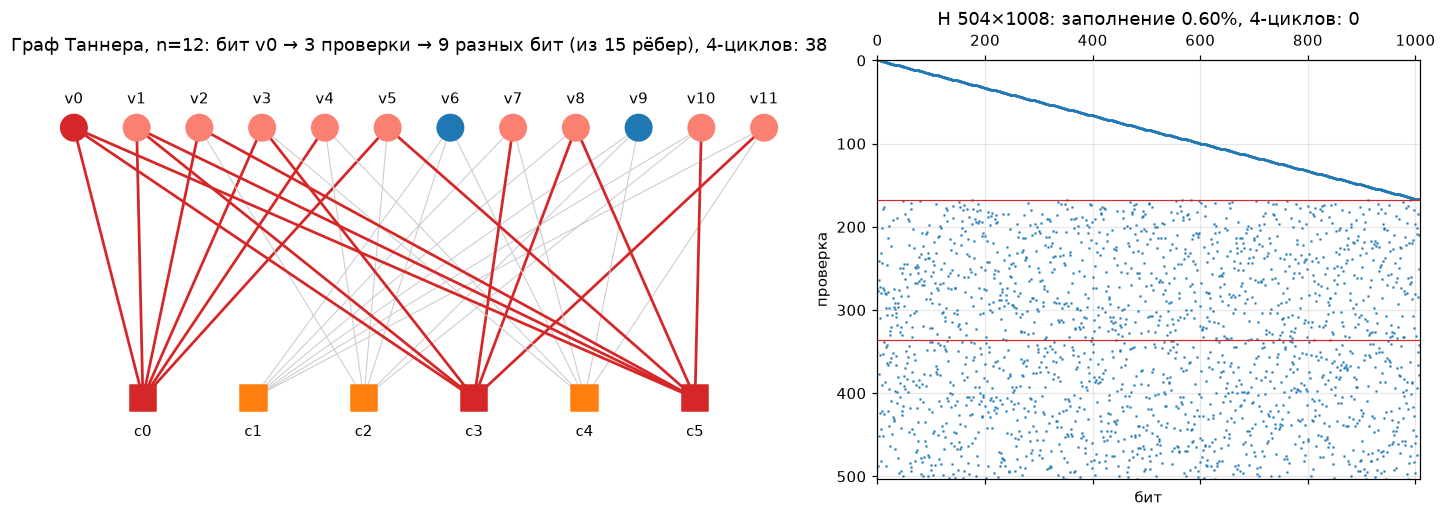

Кодер: H·cᵀ = 0 для случайных слов — True


In [3]:
Ht = gallager_H(12, DV, DC, np.random.default_rng(3), fix_4cycles=False)
mt, nt = Ht.shape
xv, xc = np.linspace(0, 1, nt), np.linspace(0.1, 0.9, mt)
hot_chk = np.nonzero(Ht[:, 0])[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a = ax[0]
for i, j in zip(*np.nonzero(Ht)):
    hot = i in hot_chk
    a.plot([xv[j], xc[i]], [1, 0], color="C3" if hot else "0.8", lw=1.8 if hot else 0.7, zorder=1)
heard = np.nonzero(Ht[hot_chk].any(0))[0]
a.scatter(xv, np.ones(nt), s=300, zorder=2, c=["C3" if j == 0 else ("salmon" if j in heard else "C0") for j in range(nt)])
a.scatter(xc, np.zeros(mt), s=300, marker="s", c=["C3" if i in hot_chk else "C1" for i in range(mt)], zorder=2)
for j in range(nt): a.text(xv[j], 1.09, f"v{j}", ha="center")
for i in range(mt): a.text(xc[i], -0.14, f"c{i}", ha="center")
a.set_ylim(-0.3, 1.25); a.axis("off")
a.set_title(f"Граф Таннера, n=12: бит v0 → {len(hot_chk)} проверки → {len(heard) - 1} разных бит (из 15 рёбер), 4-циклов: {count_4cycles(Ht)}")

ax[1].spy(H, markersize=0.4, aspect="auto")
for b in range(1, DV): ax[1].axhline(b * code.m / DV - 0.5, color="C3", lw=0.8)
ax[1].set_title(f"H {code.m}×{code.n}: заполнение {H.mean():.2%}, 4-циклов: {count_4cycles(H)}")
ax[1].set_xlabel("бит"); ax[1].set_ylabel("проверка")
plt.tight_layout(); plt.show()

U = rng.integers(0, 2, (5, code.k))
print("Кодер: H·cᵀ = 0 для случайных слов —", code.syndrome_ok(code.encode(U)).all())

## 2. Канал → LLR
При $E_b/N_0$ = `EBN0_DB` на символ приходится $E_s/N_0=R\,E_b/N_0$ — заметно меньше 0 дБ. Жёсткое решение по знаку ошибается в каждом ~8-м символе. Справа — LLR, домноженный на передаваемый знак: правильные решения справа от нуля, ошибки слева. Гауссиана $\mathcal N(\mu,2\mu)$ — теория.

Главное число — **сколько информации о бите несёт один символ** $I=J(\sqrt{8RE_b/N_0})$. Если $I>R$, код в принципе может всё исправить (Шеннон); если $I<R$ — никакой декодер не поможет.

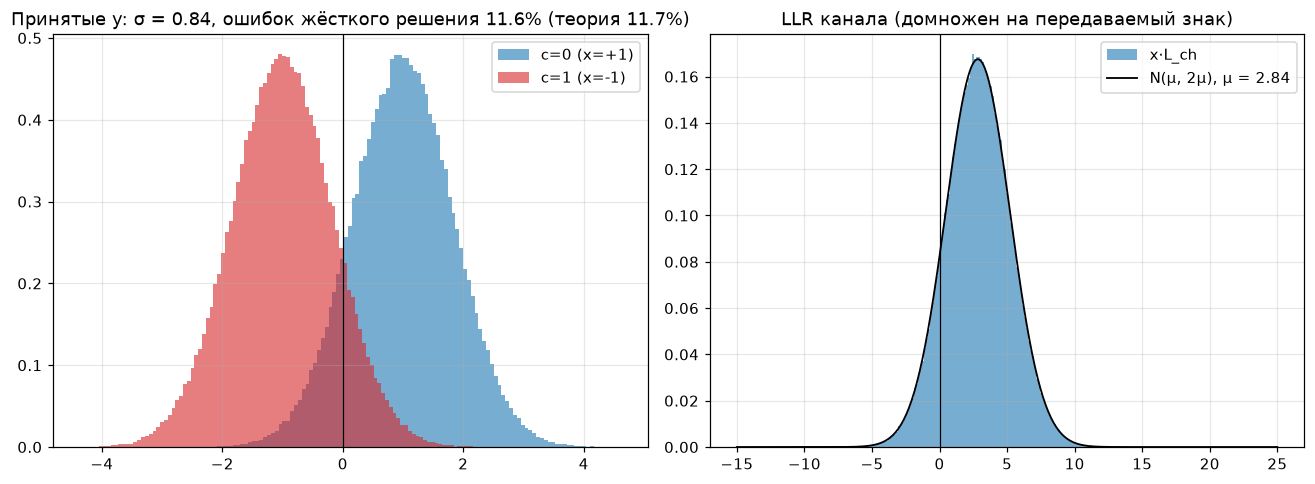

Информация на символ: измерено 0.604 бит, теория J(σ_ch) = 0.604 бит, нужно R = 0.502 бит → запас есть


In [4]:
U = rng.integers(0, 2, (400, code.k))
C = code.encode(U); X = 1 - 2.0 * C
y, L, sigma = channel(C, EBN0_DB, code.R, rng)
mu = 2 / sigma**2

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c, col in [(0, "C0"), (1, "C3")]:
    ax[0].hist(y[C == c], 120, density=True, alpha=0.6, color=col, label=f"c={c} (x={1-2*c:+d})")
ax[0].axvline(0, color="k", lw=0.8); ax[0].legend()
ax[0].set_title(f"Принятые y: σ = {sigma:.2f}, ошибок жёсткого решения {np.mean((y < 0) != C):.1%} "
                f"(теория {0.5*erfc(np.sqrt(code.R*10**(EBN0_DB/10))):.1%})")
l = np.linspace(-15, 25, 400)
ax[1].hist((L * X).ravel(), 150, density=True, alpha=0.6, label="x·L_ch")
ax[1].plot(l, np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu), "k", lw=1.2, label=f"N(μ, 2μ), μ = {mu:.2f}")
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("LLR канала (домножен на передаваемый знак)")
plt.tight_layout(); plt.show()

print(f"Информация на символ: измерено {mi(L, X):.3f} бит, теория J(σ_ch) = {J(sch(EBN0_DB, code.R)):.3f} бит, "
      f"нужно R = {code.R:.3f} бит → запас {'есть' if J(sch(EBN0_DB, code.R)) > code.R else 'НЕТ'}")

## 3. Итерации изнутри
100 кадров при `EBN0_DB`. Слева — сколько бит в кадре неверны после каждой итерации. Ошибки исчезают **лавинообразно**: пока надёжных бит мало, проверки почти ничего не дают; как только их становится достаточно, они через проверки вытягивают соседей, те — своих соседей. Часть кадров не сходится — это и есть FER на этой длине кода.

Справа — распределение апостериорного $x\cdot L$ по итерациям: масса уезжает вправо, уверенность растёт на порядки.

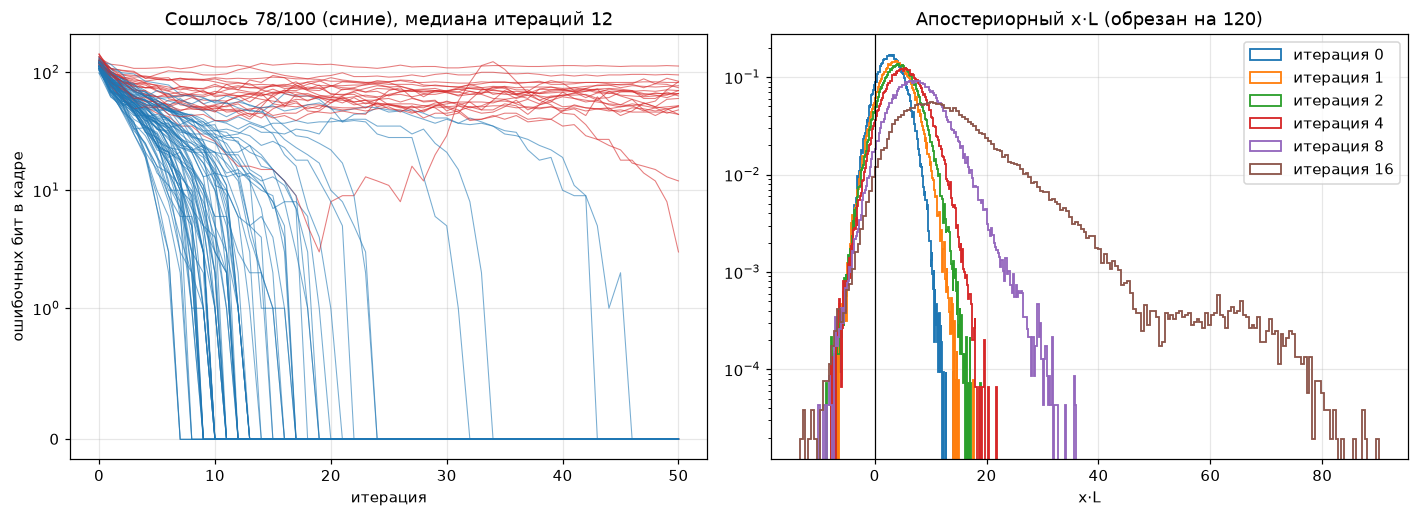

Ошибок в канале (до декодера): 118 бит на кадр из 1008 (11.7%)
После декодера: BER = 1.34e-02, FER = 0.22


In [5]:
F = 100
U = rng.integers(0, 2, (F, code.k))
C = code.encode(U); X = 1 - 2.0 * C; Xe = X[:, code.ev]
_, L, _ = channel(C, EBN0_DB, code.R, rng)
hist = []
def rec(it, Lv, Lcv):
    hist.append(dict(xL=(Lv * X).astype(np.float32), err=(Lv * X < 0).sum(1),
                     Icv=mi(Lcv, Xe), Ivc=mi(Lv[:, code.ev] - Lcv, Xe)))
Ch, nit = code.decode(L, MAX_ITER, "spa", cb=rec)
conv = code.syndrome_ok(Ch)
E = np.array([h["err"] for h in hist])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for f in range(F):
    ax[0].plot(E[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("итерация"); ax[0].set_ylabel("ошибочных бит в кадре")
ax[0].set_title(f"Сошлось {conv.sum()}/{F} (синие), медиана итераций {np.median(nit[conv]):.0f}")
for it in [0, 1, 2, 4, 8, 16]:
    if it < len(hist):
        ax[1].hist(np.clip(hist[it]["xL"].ravel(), -20, 120), 200, density=True, histtype="step", lw=1.2, label=f"итерация {it}")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("Апостериорный x·L (обрезан на 120)"); ax[1].set_xlabel("x·L")
plt.tight_layout(); plt.show()

print(f"Ошибок в канале (до декодера): {E[0].mean():.0f} бит на кадр из {code.n} ({E[0].mean()/code.n:.1%})")
print(f"После декодера: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - conv.mean():.2f}")

## 4. Порог: EXIT-диаграмма
Если сообщения на рёбрах — гауссовы LLR, каждое описывается одним числом — взаимной информацией $I$ с битом. Узел-бит и узел-проверка — это две передаточные функции $I_\text{вых}=f(I_\text{вх})$; декодер ходит между ними «лесенкой».

- **Узел-бит**: LLR складываются, складываются и их дисперсии: $I_{E,V}=J\big(\sqrt{(d_v-1)\,J^{-1}(I_A)^2+\sigma_\text{ch}^2}\big)$. От канала зависит **только эта кривая**.
- **Узел-проверка**: $I_{E,C}\approx1-J\big(\sqrt{d_c-1}\,J^{-1}(1-I_A)\big)$.

Пока между кривыми есть **туннель**, лесенка доходит до $I=1$ (безошибочно при $n\to\infty$). Порог — $E_b/N_0$, при котором туннель смыкается. Слева — ниже порога, справа — рабочая точка; точки — измеренные в симуляции раздела 3. Первые шаги симуляция повторяет теорию, дальше отстаёт: на конечном графе за ~5 итераций окрестность бита замыкается в циклы, сообщения перестают быть независимыми, а несошедшиеся кадры тянут среднее вниз.

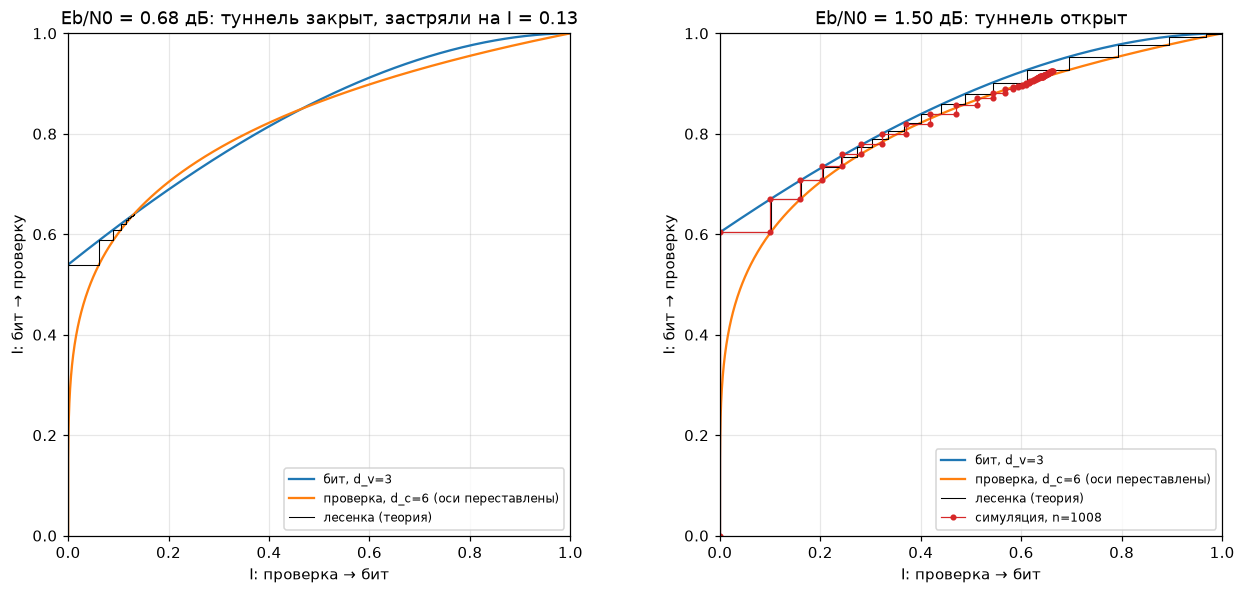

Порог по EXIT: 1.08 дБ (по точной плотностной эволюции для (3,6): 1.11 дБ), Шеннон: 0.20 дБ — регулярный код теряет 0.9 дБ; нерегулярные распределения степеней подгоняют кривые друг к другу.


In [6]:
def stairs(Ic, Iv):
    xs, ys = [Ic[0]], [0.0]
    for l in range(len(Iv)):
        xs += [Ic[l], Ic[l + 1]]; ys += [Iv[l], Iv[l]]
    return xs, ys

Ia = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, e in zip(ax, [TH - 0.4, EBN0_DB]):
    a.plot(Ia, exit_v(Ia, e, code.R), "C0", lw=1.5, label=f"бит, d_v={DV}")
    a.plot(exit_c(Ia), Ia, "C1", lw=1.5, label=f"проверка, d_c={DC} (оси переставлены)")
    Ic, Iv = de_traj(e, code.R, 300)
    a.plot(*stairs(Ic, Iv), "k", lw=0.7, label="лесенка (теория)")
    st = "открыт" if Ic[-1] > 0.9999 else f"закрыт, застряли на I = {Ic[-1]:.2f}"
    a.set_title(f"Eb/N0 = {e:.2f} дБ: туннель {st}")
    a.set_xlabel("I: проверка → бит"); a.set_ylabel("I: бит → проверку"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
Icv, Ivc = np.array([h["Icv"] for h in hist]), np.array([h["Ivc"] for h in hist])
ax[1].plot(*stairs(Icv, Ivc[:-1]), "C3o-", ms=3, lw=0.8, label="симуляция, n=%d" % code.n)
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Порог по EXIT: {TH:.2f} дБ (по точной плотностной эволюции для (3,6): 1.11 дБ), Шеннон: {SH:.2f} дБ — "
      f"регулярный код теряет {TH - SH:.1f} дБ; нерегулярные распределения степеней подгоняют кривые друг к другу.")

## 5. Водопад: BER/FER против Eb/N0
Sum-product (точный BP) и нормированный min-sum (то, что ставят в железо: только сравнения и сложения). Пунктир — предел Шеннона и EXIT-порог: порог — асимптота при $n\to\infty$, на конечной длине водопад сдвинут вправо. Справа — средняя длительность декодирования: выше по SNR декодер сходится за несколько итераций.

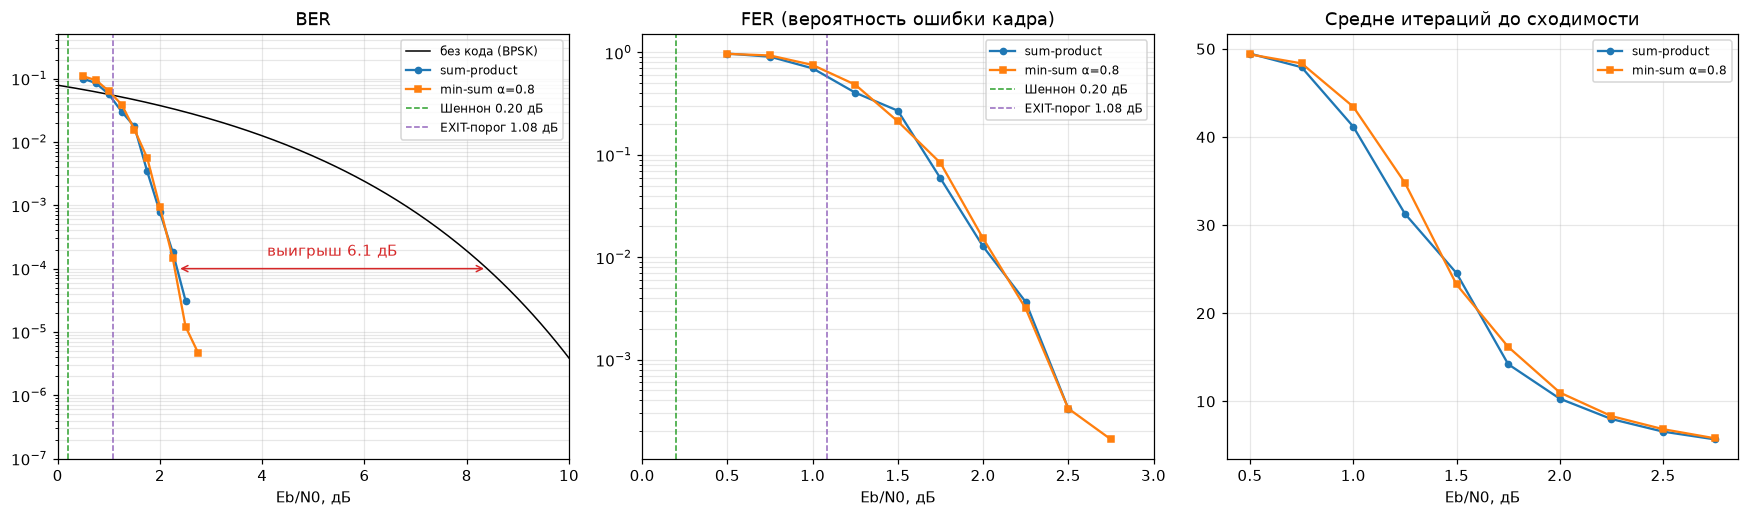

 Eb/N0 |  BER SPA   FER SPA  итер |  BER MS    FER MS   итер | кадров SPA
  0.50 |  1.0e-01  9.7e-01  49.5 |  1.1e-01  9.7e-01  49.4 | 200
  0.75 |  8.5e-02  9.1e-01  47.9 |  9.4e-02  9.4e-01  48.4 | 200
  1.00 |  5.7e-02  7.0e-01  41.2 |  6.3e-02  7.6e-01  43.4 | 200
  1.25 |  3.0e-02  4.1e-01  31.3 |  3.9e-02  4.8e-01  34.8 | 200
  1.50 |  1.8e-02  2.7e-01  24.5 |  1.6e-02  2.1e-01  23.3 | 200
  1.75 |  3.4e-03  5.9e-02  14.2 |  5.6e-03  8.3e-02  16.2 | 1000
  2.00 |  7.7e-04  1.3e-02  10.3 |  9.4e-04  1.5e-02  11.0 | 4000
  2.25 |  1.8e-04  3.7e-03   8.0 |  1.5e-04  3.2e-03   8.3 | 6000
  2.50 |  3.1e-05  3.3e-04   6.6 |  1.2e-05  3.3e-04   6.8 | 6000
  2.75 |  0.0e+00  0.0e+00   5.7 |  4.6e-06  1.7e-04   5.8 | 6000

BER = 1e-04: без кода 8.4 дБ, LDPC 2.3 дБ → выигрыш кодирования 6.1 дБ ценой удвоения полосы (R = 1/2)


In [7]:
def simulate(ebn0_list, algo, min_fe=50, max_frames=6000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = its = 0
        while fe < min_fe and nf < max_frames:
            U = rng.integers(0, 2, (batch, code.k))
            _, L, _ = channel(code.encode(U), e, code.R, rng)
            Ch, nit = code.decode(L, MAX_ITER, algo, ALPHA_MS)
            err = Ch[:, code.info] != U
            be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * code.k), fe / nf, its / nf, nf))
    return np.array(res)

ebn0 = np.arange(0.5, 2.76, 0.25)
res = {"sum-product": simulate(ebn0, "spa"), f"min-sum α={ALPHA_MS}": simulate(ebn0, "ms")}

r = res["sum-product"]
target = 1e-4                                      # ниже статистики мало (0 ошибок на 6000 кадров ≠ BER 0)
i = np.argmax((r[:, 0] < target) & (r[:, 0] > 0))  # первая ненулевая точка ниже цели, интерполяция по log BER
e_code = np.interp(np.log10(target), np.log10(r[[i, i - 1], 0]), ebn0[[i, i - 1]])
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)

eb = np.linspace(0, 10, 200)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k-", lw=1, label="без кода (BPSK)")
for (name, rr), mk in zip(res.items(), "os"):
    ok = rr[:, 0] > 0
    ax[0].semilogy(ebn0[ok], rr[ok, 0], mk + "-", ms=4, label=name)
    ax[1].semilogy(ebn0[rr[:, 1] > 0], rr[rr[:, 1] > 0, 1], mk + "-", ms=4, label=name)
    ax[2].plot(ebn0, rr[:, 2], mk + "-", ms=4, label=name)
for a in ax[:2]:
    a.axvline(SH, color="C2", ls="--", lw=1, label=f"Шеннон {SH:.2f} дБ")
    a.axvline(TH, color="C4", ls="--", lw=1, label=f"EXIT-порог {TH:.2f} дБ")
ax[0].annotate("", xy=(e_code, target), xytext=(e_unc, target), arrowprops=dict(arrowstyle="<->", color="C3"))
ax[0].text((e_code + e_unc) / 2, target * 1.6, f"выигрыш {e_unc - e_code:.1f} дБ", color="C3", ha="center")
ax[0].set_xlim(0, 10); ax[0].set_ylim(1e-7, 0.5)
ax[1].set_xlim(0, 3)
ax[0].set_title("BER"); ax[1].set_title("FER (вероятность ошибки кадра)"); ax[2].set_title("Средне итераций до сходимости")
for a in ax: a.set_xlabel("Eb/N0, дБ"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(" Eb/N0 |  BER SPA   FER SPA  итер |  BER MS    FER MS   итер | кадров SPA")
for i, e in enumerate(ebn0):
    s, q = list(res.values())[0][i], list(res.values())[1][i]
    print(f" {e:5.2f} | {s[0]:8.1e} {s[1]:8.1e} {s[2]:5.1f} | {q[0]:8.1e} {q[1]:8.1e} {q[2]:5.1f} | {int(s[3])}")

print(f"\nBER = {target:.0e}: без кода {e_unc:.1f} дБ, LDPC {e_code:.1f} дБ → выигрыш кодирования {e_unc - e_code:.1f} дБ "
      f"ценой удвоения полосы (R = 1/2)")

## Сравнение с CDMA
DSSS из соседнего ноутбука — это тоже код, **код повторения** со скоростью $R=1/N$: бит просто повторяется $N$ раз. Против белого шума он не даёт ничего (кривая = BPSK): энергия бита та же, просто размазана по $N$ чипам. LDPC при $R=1/2$ даёт 6–7 дБ: проверочные биты не копируют данные, а **связывают** их, и каждая ошибка должна «пробиться» через несколько независимых ограничений.

| | DSSS (повторение) | LDPC (3,6) |
|---|---|---|
| Избыточность | $N=1023$ | 2 |
| Выигрыш против AWGN (BER $10^{-4}$…$10^{-5}$) | 0 дБ | 6–7 дБ |
| Против узкополосной помехи | $10\log_{10}N$ = 30 дБ | ~0 (нужен перемежитель) |
| Декодер | один коррелятор | итеративный обмен LLR |

В реальных системах они работают вместе: спрединг/OFDM разбирается с каналом, код — с остаточным шумом. В LTE данные кодируются турбо-кодом (тот же принцип итеративного обмена LLR, два свёрточных кода вместо графа); LDPC пришёл в 5G NR и Wi-Fi — квазициклические матрицы, собранные из циклических сдвигов единичных блоков $Z\times Z$, чтобы декодер был параллельным.

## Что покрутить
- `EBN0_DB = 1.0` — ниже порога: в разделе 4 туннель закрыт, в разделе 3 почти все кадры застревают с сотней ошибок
- `N_CODE = 96` / `4032` — водопад становится круче с длиной и прижимается к EXIT-порогу, сам порог не меняется
- `DV, DC = 4, 8` (та же $R=1/2$) — порог хуже (~1.5 дБ): больше рёбер — больше ограничений, но каждое слабее
- `ALPHA_MS = 1.0` — чистый min-sum переоценивает уверенность проверок ($\min|L|$ больше точного значения) и заметно проигрывает; нормировка это компенсирует. На высоком SNR нормированный min-sum бывает даже лучше точного BP: на графе с циклами BP сам «пересамоуверен»
- в `gallager_H(..., fix_4cycles=False)` — оставить 4-циклы и посмотреть на ошибочное «эхо» в BP